<a href="https://colab.research.google.com/github/sichaoj/Stats_ML_AI/blob/main/LogTransform_II.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Follow up on A/B testing: how to handle heavily skewed data?

**Context:** In my [last post](https://sichaoj.github.io/writeups/ab-testing-skewed-data.html), I explored why analyzing heavily right-skewed data can be challenging. Specifically, extreme skewness may require a substantially larger sample size to achieve sufficient statistical power, increasing the risk of Type II errors.

However, my original simulation overlooked an important part of real-world business metrics: **heavily right-skewed data often contain a large proportion of zeros**, making a direct log transformation problematic since log(0) is undefined.

**Question:** What is the best way to handle zero-inflated, heavily right-skewed data in A/B testing?

In this reproducible example, I:

1. Simulate two heavily right-skewed, zero-inflated revenue distributions.
2. Apply Welch's two-sample t-test to different common metric transformtion methods: raw, $log(x + 1), log(x + \varepsilon)$, standard normalization, and Box-Cox.
3. Compare mean differences, and p-values across sample sizes and across different proportion of zeros.
4. Discuss how zero inflation and metric transformations affect statistical significance, interpretation, and A/B-test launch decisions.


,n,Control Zero Rate,Treatment Zero Rate,Method,Control Mean,Treatment Mean,Mean Diff,P-value
0,1000,0.2,0.15,Raw,10.0000,14.0000,4.0000,0.0457
1,1000,0.2,0.15,Log1p,1.2636,1.4561,0.1925,0.0008
2,1000,0.2,0.15,Log(1e-6+x),-1.9651,-1.0650,0.9001,0.0006
3,1000,0.2,0.15,Normalization,-0.0447,0.0447,0.0894,0.0457
4,1000,0.2,0.15,Box-Cox,0.8441,0.9541,0.1100,0.0004
5,2000,0.2,0.15,Raw,10.0000,14.0000,4.0000,0.0130
6,2000,0.2,0.15,Log1p,1.2560,1.4115,0.1555,0.0001
7,2000,0.2,0.15,Log(1e-6+x),-1.9879,-1.1185,0.8694,0.0000
8,2000,0.2,0.15,Normalization,-0.0393,0.0393,0.0786,0.0130
9,2000,0.2,0.15,Box-Cox,0.8216,0.9092,0.0876,0.0000


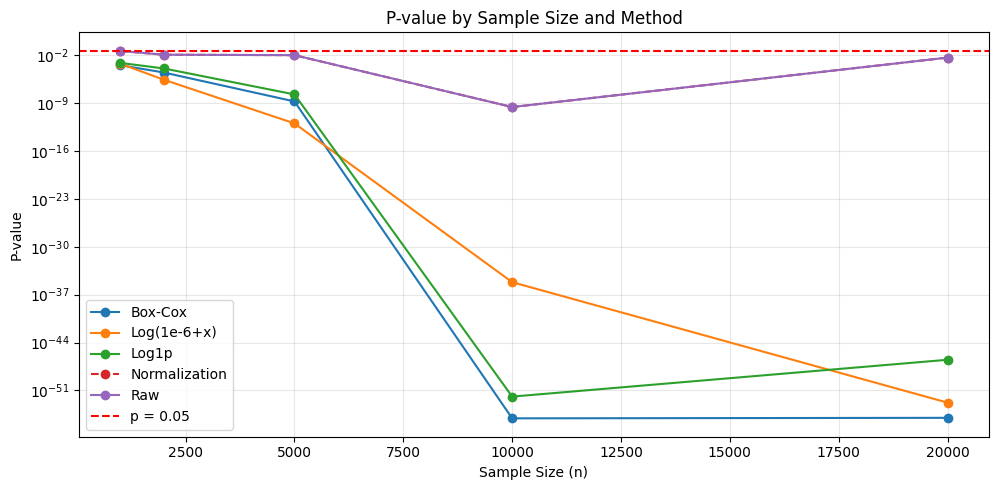

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind

def run_simulation(n=1000, control_zero_rate=0.25, treatment_zero_rate=0.20, seed=42, return_data=False):
    rng = np.random.default_rng(seed)

    # Simulate revenue with group-specific zero rates
    def simulate_revenue(target_mean, zero_rate):
        n_zeros = int(n * zero_rate)

        rev = np.concatenate([
            np.zeros(n_zeros),
            rng.lognormal(mean=2, sigma=1.8, size=n - n_zeros)
        ])

        rng.shuffle(rev)

        # Scale revenue to achieve the target group mean
        rev *= target_mean / rev.mean()
        return rev

    control = simulate_revenue(10, control_zero_rate)
    treatment = simulate_revenue(14, treatment_zero_rate)

    # Create dataset
    df = pd.DataFrame({
        "group": ["Control"] * n + ["Treatment"] * n,
        "rev": np.concatenate([control, treatment])
    })

    # Use the same transformation parameters for both groups
    pooled = np.concatenate([control, treatment])
    pooled_mean, pooled_std = pooled.mean(), pooled.std()
    from scipy.stats import boxcox
    # Box-Cox requires positive values; add 1 to handle zeros
    boxcox_values, boxcox_lambda = boxcox(pooled + 1)

    # Five direct t-test methods
    methods = {
        "Raw": (control, treatment),
        "Log1p": (np.log1p(control), np.log1p(treatment)),
        "Log(1e-6+x)": (np.log(1e-6 + control), np.log(1e-6 + treatment)),
        "Normalization": ((control - pooled_mean) / pooled_std,
                          (treatment - pooled_mean) / pooled_std),
        "Box-Cox": (boxcox_values[:n], boxcox_values[n:])
    }

    results = []

    for method, (c, t) in methods.items():
        results.append({
            "n": n,
            "Control Zero Rate": control_zero_rate,
            "Treatment Zero Rate": treatment_zero_rate,
            "Method": method,
            "Control Mean": c.mean(),
            "Treatment Mean": t.mean(),
            "Mean Diff": t.mean() - c.mean(),
            "P-value": ttest_ind(t, c, equal_var=False).pvalue
        })

    results = pd.DataFrame(results)
    return (results, df) if return_data else results


# Parameters (n is sample size per group)
n_values = [1000, 2000, 5000, 10000, 20000]
control_zero_rate = 0.20
treatment_zero_rate = 0.15

results = pd.concat([
    run_simulation(n, control_zero_rate, treatment_zero_rate)
    for n in n_values
], ignore_index=True)

display(results.round(4))

# Keep one simulated dataset for further analysis
n = n_values[0]
_, df = run_simulation(n, control_zero_rate, treatment_zero_rate, return_data=True)
control = df.loc[df.group == "Control", "rev"]
treatment = df.loc[df.group == "Treatment", "rev"]

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for method, group in results.groupby("Method"):
    group = group.sort_values("n")
    plt.plot(group["n"], group["P-value"],
             marker="o", label=method,
             linestyle="--" if method == "Normalization" else "-")

# Statistical significance threshold
plt.axhline(y=0.05, color="red", linestyle="--", label="p = 0.05")

plt.xlabel("Sample Size (n)")
plt.ylabel("P-value")
plt.title("P-value by Sample Size and Method")
plt.tight_layout()
plt.legend()
plt.yscale("log")
plt.grid(alpha=0.3)
plt.show()


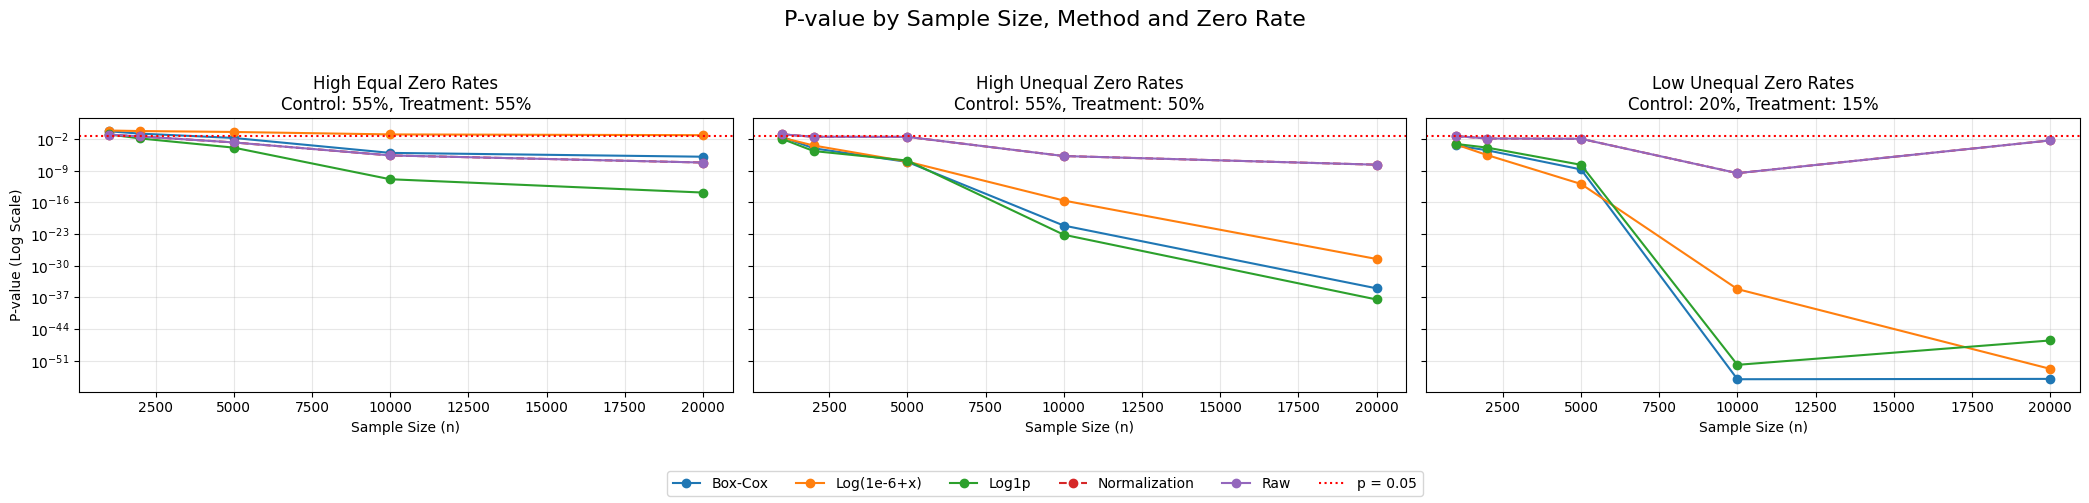

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(21, 5), sharey=True)

scenarios = [
    (0.55, 0.55, "High Equal Zero Rates"),
    (0.55, 0.50, "High Unequal Zero Rates"),
    (0.20, 0.15, "Low Unequal Zero Rates")
]

for ax, (c_rate, t_rate, title) in zip(axes, scenarios):

    results = pd.concat([
        run_simulation(n, c_rate, t_rate)
        for n in n_values
    ], ignore_index=True)

    for method, group in results.groupby("Method"):
        group = group.sort_values("n")

        ax.plot(
            group["n"],
            group["P-value"],
            marker="o",
            linestyle="--" if method == "Normalization" else "-",
            label=method
        )

    # Statistical significance threshold
    ax.axhline(y=0.05, color="red", linestyle=":", label="p = 0.05")

    # Logarithmic y-axis
    ax.set_yscale("log")

    ax.set_xlabel("Sample Size (n)")
    ax.set_title(
        f"{title}\nControl: {c_rate:.0%}, Treatment: {t_rate:.0%}"
    )
    ax.grid(alpha=0.3)

axes[0].set_ylabel("P-value (Log Scale)")

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6)

# Overall title
fig.suptitle(
    "P-value by Sample Size, Method and Zero Rate",
    fontsize=16
)

plt.tight_layout(rect=[0, 0.1, 1, 0.95])
plt.show()

## Conclusions and Takeaways

- **Log(x + ε) is highly sensitive to differences in zero rates:** When zero rates are identical, this transformation performs poorly because the extreme negative values assigned to zeros inflate variance without contributing to the between-group mean difference. When zero rates differ, however, these extreme values amplify the difference in the proportion of positive observations, resulting in substantially smaller p-values.

- **Log1p is more robust across zero-inflation scenarios:** Log1p compresses extreme positive values while mapping zeros naturally to zero. Unlike Log(x + ε), it avoids introducing extreme negative values and remains sensitive to changes in both the proportion of positive observations and the magnitude of positive revenue. It produces consistently smaller p-values than the raw test across the simulated scenarios.

- **Box-Cox is adaptive but distribution-dependent:** Box-Cox estimates the transformation parameter λ based on the observed distribution. Its performance is comparable to Log1p in the unequal-zero-rate scenarios but less favorable in the high equal-zero-rate scenario. Its sensitivity depends on the underlying distribution, zero inflation, and the constant added before transformation.

- **The degree of zero inflation also matters:** With the same 5-percentage-point difference in zero rates, nonlinear transformations produce generally smaller p-values at larger sample sizes when overall zero rates are lower. This suggests that transformation performance depends on both the absolute level of zero inflation and the difference between groups.

- **Normalization is not variance reduction:** A shared z-score transformation leaves Welch's t-statistic and p-value unchanged; it changes the units, not the distribution's skewness.

- **Statistical significance is not the same as business impact:** Log and Box-Cox transformations test differences in transformed means, not arithmetic mean revenue. For a launch decision based on incremental revenue, retain raw revenue as the primary estimand and use transformed metrics and the positive-revenue rate as complementary diagnostics.

- **Smaller p-values do not necessarily imply higher statistical power:** These curves represent individual simulation realizations. Repeated simulations are needed to formally compare statistical power and distinguish systematic patterns from sampling variability.